# Taller 11: Máquinas de Soporte Vectorial
**Inteligencia Artificial – ELP 8012 – Universidad del Norte**
Profesor: Eduardo Zurek, Ph.D.

**Integrantes:**
- Bryan Montoya
- Andrea Quintero
- Wilmer Santiago

---

## Objetivo
Diseñar e implementar una Máquina de Soporte Vectorial (SVM) que clasifique los dígitos escritos a mano del dataset `digits` de scikit-learn, encontrar el tipo de kernel con mejor desempeño usando validación cruzada k-fold y comparar los resultados con los talleres 9 (Naive Bayes) y 10 (redes neuronales).

## Metodología
1. Carga y exploración del dataset.
2. División estratificada 80 % entrenamiento / 20 % prueba (misma partición que el taller 9).
3. Comparación de los kernels `linear`, `poly`, `rbf` y `sigmoid` con `StratifiedKFold(k=4)` sobre el 80 % de entrenamiento (se reporta media y desviación estándar).
4. Búsqueda de hiperparámetros (`C`, `gamma`, `degree`) del mejor kernel con k-fold.
5. Evaluación final sobre el 20 % de prueba y comparación con los talleres 9 y 10.

In [1]:
import time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)
warnings.filterwarnings('ignore'); sns.set_theme(style='whitegrid')
SEED=42; K=4

## 1. Carga y exploración del dataset

`digits` contiene 1 797 imágenes de 8×8 píxeles (64 características con valores enteros 0–16) y 10 clases.

X: (1797, 64) | y: (1797,) | clases: [0 1 2 3 4 5 6 7 8 9]
Rango de píxeles: 0.0 - 16.0
Muestras por clase: [178 182 177 183 181 182 181 179 174 180]


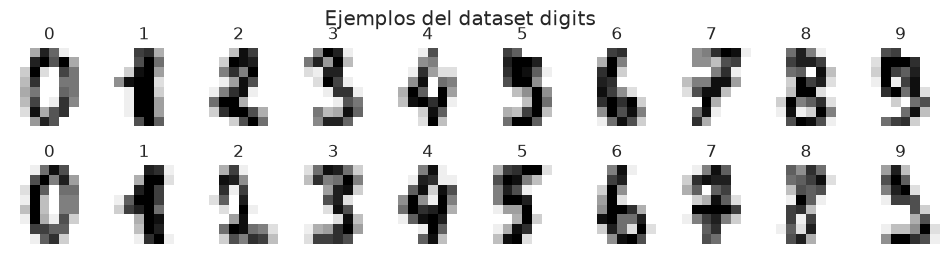

In [2]:
digits = load_digits()
X, y = digits.data, digits.target
print('X:', X.shape, '| y:', y.shape, '| clases:', np.unique(y))
print('Rango de píxeles:', X.min(), '-', X.max())
print('Muestras por clase:', np.bincount(y))
fig, axs = plt.subplots(2, 10, figsize=(12, 2.8))
for ax, img, lab in zip(axs.ravel(), digits.images, y):
    ax.imshow(img, cmap='gray_r'); ax.set_title(lab); ax.axis('off')
plt.suptitle('Ejemplos del dataset digits'); plt.show()

## 2. División 80 % entrenamiento / 20 % prueba

División estratificada con `random_state=42`. El conjunto de prueba no se usa hasta la evaluación final.

In [3]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print('Entrenamiento:', X_tr.shape, '| Prueba:', X_te.shape)

Entrenamiento: (1437, 64) | Prueba: (360, 64)


## 3. Comparación de kernels con k-fold (k = 4)

Las SVM son sensibles a la escala, por eso se usa un `Pipeline` con `StandardScaler` (se ajusta dentro de cada fold para evitar fuga de datos). Se prueban los cuatro kernels con hiperparámetros por defecto (`C=1`, `gamma='scale'`, `degree=3`).

In [4]:
skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=SEED)
scoring = {'accuracy':'accuracy','precision':'precision_macro','recall':'recall_macro','f1':'f1_macro'}
rows=[]
for kern in ['linear','poly','rbf','sigmoid']:
    pipe = make_pipeline(StandardScaler(), SVC(kernel=kern, random_state=SEED))
    r = cross_validate(pipe, X_tr, y_tr, cv=skf, scoring=scoring, return_train_score=True)
    rows.append({'kernel':kern,
        'accuracy':r['test_accuracy'].mean(), 'acc_std':r['test_accuracy'].std(),
        'precision':r['test_precision'].mean(), 'recall':r['test_recall'].mean(),
        'f1':r['test_f1'].mean(), 'acc_train':r['train_accuracy'].mean(),
        'fit_time_s':r['fit_time'].mean()})
res = pd.DataFrame(rows).set_index('kernel').round(4)
print(f'Resultados con StratifiedKFold(k={K}) sobre el conjunto de entrenamiento')
display(res)
best_kernel = res['accuracy'].idxmax()
print('Mejor kernel por accuracy medio de validación:', best_kernel)

Resultados con StratifiedKFold(k=4) sobre el conjunto de entrenamiento


,accuracy,acc_std,precision,recall,f1,acc_train,fit_time_s
kernel,,,,,,,
linear,0.9756,0.0075,0.9763,0.9754,0.9754,1.0000,0.0156
poly,0.9457,0.0063,0.9599,0.9459,0.9482,0.9745,0.0333
rbf,0.9812,0.0093,0.9815,0.9811,0.9811,0.9974,0.0322
sigmoid,0.9436,0.0023,0.9452,0.9435,0.9432,0.9573,0.0278


Mejor kernel por accuracy medio de validación: rbf


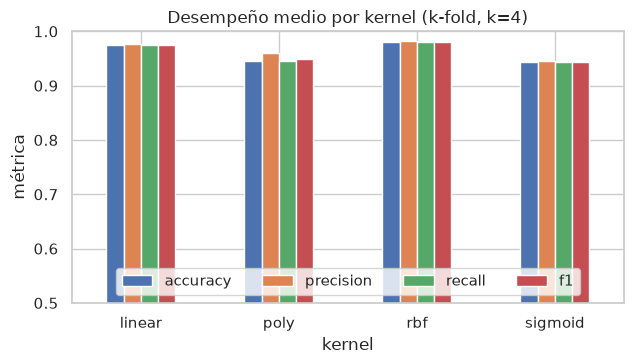

In [5]:
ax = res[['accuracy','precision','recall','f1']].plot(kind='bar', figsize=(6.5,3.8), ylim=(0.5,1.0))
ax.set_title('Desempeño medio por kernel (k-fold, k=4)'); ax.set_ylabel('métrica'); plt.xticks(rotation=0); plt.legend(loc='lower center', ncol=4); plt.tight_layout(); plt.show()

## 4. Ajuste de hiperparámetros del mejor kernel

Se hace `GridSearchCV` con el mismo k-fold sobre el conjunto de entrenamiento para el kernel ganador, y también para `poly` (grado) como contraste.

In [6]:
grids = {
 'rbf':  {'svc__C':[0.1,1,10,100], 'svc__gamma':['scale',0.001,0.003,0.01,0.03]},
 'poly': {'svc__C':[0.1,1,10,100], 'svc__degree':[2,3,4], 'svc__gamma':['scale',0.003,0.01]},
 'linear':{'svc__C':[0.001,0.01,0.1,1,10]},
 'sigmoid':{'svc__C':[0.1,1,10,100], 'svc__gamma':['scale',0.001,0.003,0.01]},
}
tuned={}
for kern,g in grids.items():
    gs = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel=kern, random_state=SEED)), g,
                      cv=skf, scoring='accuracy', n_jobs=-1)
    gs.fit(X_tr, y_tr); tuned[kern]=gs
    print(f'{kern:8s} mejor acc CV = {gs.best_score_:.4f} | {gs.best_params_}')
best_kernel = max(tuned, key=lambda k: tuned[k].best_score_)
print('\nKernel ganador tras ajuste:', best_kernel)

rbf      mejor acc CV = 0.9819 | {'svc__C': 10, 'svc__gamma': 'scale'}


poly     mejor acc CV = 0.9833 | {'svc__C': 100, 'svc__degree': 3, 'svc__gamma': 'scale'}


linear   mejor acc CV = 0.9777 | {'svc__C': 0.1}


sigmoid  mejor acc CV = 0.9791 | {'svc__C': 10, 'svc__gamma': 0.003}

Kernel ganador tras ajuste: poly


## 5. Evaluación final en el conjunto de prueba (20 %)

SVM kernel=poly {'svc__C': 100, 'svc__degree': 3, 'svc__gamma': 'scale'}
Accuracy: 0.9944
Precision (macro): 0.9945
Recall (macro): 0.9944
F1 (macro): 0.9944
Tiempo de entrenamiento: 0.051s | vectores de soporte: 649 de 1437

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        36
           1     1.0000    1.0000    1.0000        36
           2     1.0000    1.0000    1.0000        35
           3     1.0000    1.0000    1.0000        37
           4     1.0000    1.0000    1.0000        36
           5     1.0000    1.0000    1.0000        37
           6     1.0000    0.9722    0.9859        36
           7     0.9730    1.0000    0.9863        36
           8     0.9722    1.0000    0.9859        35
           9     1.0000    0.9722    0.9859        36

    accuracy                         0.9944       360
   macro avg     0.9945    0.9944    0.9944       360
weighted avg     0.9946    0.9944    0.9944       360



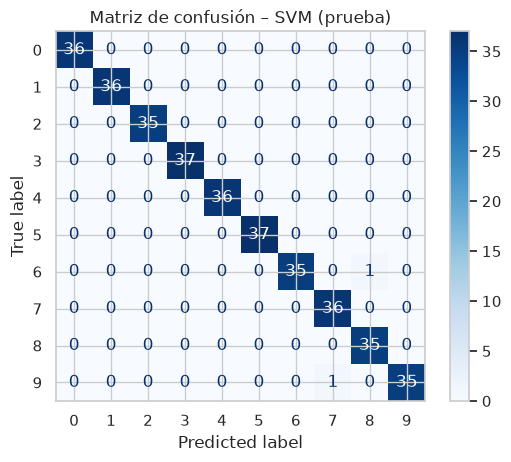

In [7]:
model = tuned[best_kernel].best_estimator_
t=time.time(); model.fit(X_tr, y_tr); fit_t=time.time()-t
y_pr = model.predict(X_te)
acc=accuracy_score(y_te,y_pr); pre=precision_score(y_te,y_pr,average='macro')
rec=recall_score(y_te,y_pr,average='macro'); f1=f1_score(y_te,y_pr,average='macro')
print(f'SVM kernel={best_kernel} {tuned[best_kernel].best_params_}')
print(f'Accuracy: {acc:.4f}\nPrecision (macro): {pre:.4f}\nRecall (macro): {rec:.4f}\nF1 (macro): {f1:.4f}')
print(f'Tiempo de entrenamiento: {fit_t:.3f}s | vectores de soporte: {model[-1].n_support_.sum()} de {len(X_tr)}')
print(); print(classification_report(y_te, y_pr, digits=4))
ConfusionMatrixDisplay.from_predictions(y_te, y_pr, cmap='Blues'); plt.title('Matriz de confusión – SVM (prueba)'); plt.show()

Errores: 2 de 360


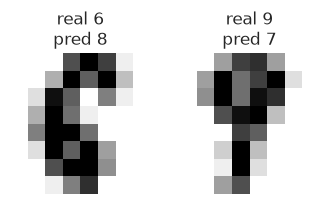

In [8]:
# Errores cometidos (evidencia)
err = np.where(y_pr!=y_te)[0]
print('Errores:', len(err), 'de', len(y_te))
if len(err):
    fig, axs = plt.subplots(1, len(err), figsize=(2*len(err), 2.4), squeeze=False)
    for ax,i in zip(axs[0],err):
        ax.imshow(X_te[i].reshape(8,8), cmap='gray_r'); ax.set_title(f'real {y_te[i]}\npred {y_pr[i]}'); ax.axis('off')
    plt.show()

In [9]:
# Rendimiento en prueba de los 4 kernels ya ajustados
rows=[]
for kern,gs in tuned.items():
    p=gs.best_estimator_.fit(X_tr,y_tr).predict(X_te)
    rows.append({'kernel':kern,'acc_CV':gs.best_score_,'acc_prueba':accuracy_score(y_te,p),
                 'f1_prueba':f1_score(y_te,p,average='macro'),'params':gs.best_params_})
final=pd.DataFrame(rows).set_index('kernel'); final[['acc_CV','acc_prueba','f1_prueba']]=final[['acc_CV','acc_prueba','f1_prueba']].round(4)
display(final)

,acc_CV,acc_prueba,f1_prueba,params
kernel,,,,
rbf,0.9819,0.9806,0.9805,"{'svc__C': 10, 'svc__gamma': 'scale'}"
poly,0.9833,0.9944,0.9944,"{'svc__C': 100, 'svc__degree': 3, 'svc__gamma'..."
linear,0.9777,0.9833,0.9831,{'svc__C': 0.1}
sigmoid,0.9791,0.9806,0.9806,"{'svc__C': 10, 'svc__gamma': 0.003}"


## 6. Comparación con los talleres 9 y 10 (en igualdad de condiciones)

Los talleres 9 y 10 usaron particiones distintas entre sí (el 9 estratificada, el 10 sin estratificar), así que comparar sus cifras publicadas no es exacto. Para que sea justo, **se reentrenan aquí los mejores modelos de cada taller con la misma partición 80/20 y los mismos folds** que la SVM:

- **Taller 9:** `CategoricalNB(alpha=0.2, min_categories=17)`.
- **Taller 10:** `MLPClassifier(hidden_layer_sizes=(100,), activation='relu', max_iter=1000, random_state=42)` con `StandardScaler`.
- **Taller 11:** la SVM ganadora de la sección 5.

Se reportan el k-fold (k = 4) sobre entrenamiento y el resultado en prueba.

,Acc CV (media),Acc CV (std),Acc prueba,Precision,Recall,F1,Errores (de 360),Entrenamiento (s)
Modelo,,,,,,,,
Taller 9 – CategoricalNB (α=0.2),0.9109,0.0117,0.9083,0.9094,0.9081,0.9081,33,0.0172
Taller 10 – MLP (relu),0.9749,0.0056,0.9750,0.9748,0.9747,0.9746,9,1.8636
Taller 11 – SVM (poly),0.9833,0.0048,0.9944,0.9945,0.9944,0.9944,2,0.0544


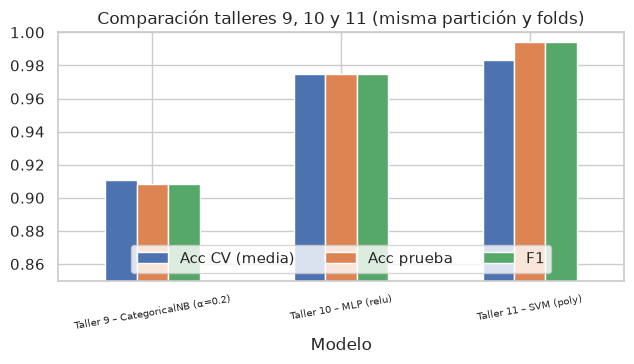

In [10]:
from sklearn.naive_bayes import CategoricalNB
from sklearn.neural_network import MLPClassifier
from sklearn.base import clone
svm_final = tuned[best_kernel].best_estimator_
candidatos = {
  'Taller 9 – CategoricalNB (α=0.2)': CategoricalNB(alpha=0.2, min_categories=17),
  'Taller 10 – MLP (relu)': make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(100,), activation='relu', max_iter=1000, random_state=SEED)),
  f'Taller 11 – SVM ({best_kernel})': svm_final,
}
rows=[]
for nombre, est in candidatos.items():
    cv = cross_validate(clone(est), X_tr, y_tr, cv=skf, scoring=scoring)
    t=time.time(); m=clone(est).fit(X_tr,y_tr); tt=time.time()-t
    p=m.predict(X_te)
    rows.append({'Modelo':nombre,
      'Acc CV (media)':cv['test_accuracy'].mean(), 'Acc CV (std)':cv['test_accuracy'].std(),
      'Acc prueba':accuracy_score(y_te,p), 'Precision':precision_score(y_te,p,average='macro'),
      'Recall':recall_score(y_te,p,average='macro'), 'F1':f1_score(y_te,p,average='macro'),
      'Errores (de 360)':int((p!=y_te).sum()), 'Entrenamiento (s)':tt})
comp = pd.DataFrame(rows).set_index('Modelo').round(4)
display(comp)
comp[['Acc CV (media)','Acc prueba','F1']].plot(kind='bar', figsize=(6.5,3.8), ylim=(0.85,1.0))
plt.xticks(rotation=10, fontsize=7); plt.legend(loc='lower center', ncol=3); plt.title('Comparación talleres 9, 10 y 11 (misma partición y folds)'); plt.tight_layout(); plt.show()

## 7. Análisis y conclusiones

**Kernels (k-fold, k = 4, hiperparámetros por defecto):** `rbf` 0,9812 > `linear` 0,9756 > `poly` 0,9457 > `sigmoid` 0,9436. Con valores por defecto el kernel RBF es el mejor.

**Tras ajustar `C`, `gamma` y `degree` con k-fold:** `poly` (grado 3, C = 100) 0,9833, `rbf` (C = 10) 0,9819, `sigmoid` 0,9791 y `linear` (C = 0,1) 0,9777. La diferencia entre `poly` y `rbf` (0,0014) es mucho menor que la desviación estándar entre folds (≈ 0,009), así que **no es estadísticamente concluyente**: ambos kernels no lineales son equivalentes en validación. Se selecciona `poly` por tener el mayor accuracy medio de validación, criterio fijado antes de mirar el conjunto de prueba.

**Prueba (20 %):** el SVM `poly` obtiene accuracy 0,9944 (2 errores en 360), precision 0,9945, recall 0,9944 y F1 0,9944. El modelo `rbf` ajustado obtiene 0,9806. Esta brecha de ~5 imágenes en 360 se debe en parte al azar de la partición, por eso la validación cruzada es la medida más estable.

**Observaciones:**
- `digits` es casi linealmente separable (el kernel `linear` ya alcanza ≈ 0,98), pero los kernels no lineales aportan un margen pequeño.
- Se estandariza con `StandardScaler` dentro de cada fold para evitar fuga de datos; las SVM son sensibles a la escala.
- `C` controla el compromiso margen/sobreajuste; con `poly` un `C` alto (100) fue preferido. `sigmoid` con valores por defecto rinde mal y mejora solo al ajustar `gamma`.
- Se usan 649 de 1 437 vectores de soporte (45 %).

**Comparación con talleres anteriores (misma partición y folds, sección 6):** SVM `poly` 0,9833 en k-fold y 0,9944 en prueba (2 errores), MLP relu del taller 10 0,9749 y 0,9750 (9 errores), y CategoricalNB del taller 9 0,9109 y 0,9083 (33 errores). La SVM es la mejor en ambas medidas, y su ventaja sobre el MLP en validación cruzada (≈ 0,008) es del orden de la desviación entre folds (0,005–0,006), por lo que es moderada. Naive Bayes queda ≈ 7 puntos por debajo porque asume independencia entre píxeles. Con la partición no estratificada original del taller 10 el MLP obtuvo 0,9806; aquí 0,9750, lo que muestra la variabilidad de una sola partición. La SVM también es determinista y entrena en ≈ 0,05 s frente a ≈ 2,7 s del MLP.